# Lab 1 &ndash; Running Grover on Qiskit

Please indicate here the names of the coworkers on this notebook:

- <span style="color: blue">CACHEUX Nolan</span>
- <span style="color: blue">EVAIN Sacha</span>
- <span style="color: blue">HAGE Rémi</span>
- <span style="color: blue">$\ldots$</span>

## A) Introduction to Qiskit

So far we used IBM Q's Composer interface to construct, execute and simulate quantum circuits, but the [Qiskit](https://www.ibm.com/quantum/qiskit) library provides a much more versatile and powerful way to manipulate these from a Jupyter notebook such as this one. You can run it locally on your computer by making sure you have the `qiskit`, `qiskit-aer` and `qiskit-ibm-runtime` libraries installed or in an online environement such as Google Colab (more details [here](https://docs.quantum.ibm.com/guides/install-qiskit)).

So make sure you have the Qiskit library for Python installed, then start by importing the features we will be using today:

In [ ]:
# In your Python (<=3.13 at time of writing) environment:
!pip install qiskit qiskit-aer qiskit-ibm-runtime matplotlib

from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_state_city, plot_histogram
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import Aer
from qiskit_ibm_runtime import SamplerV2 as Sampler, QiskitRuntimeService

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 110.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 89.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 378.6/378.6 kB 29.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.4/54.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 5.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.2/130.2 kB 10.2 MB/s eta 0:00:00


Let us start by recreating one of our simplest circuits:

In [ ]:
circ = QuantumCircuit(2)  # create a circuit with 2 qubits, q_0 and q_1
circ.h(0)                 # apply an H-gate on q_0
circ.cx(0,1)              # apply an X-gate on q_1 controlled by q_0
circ.draw()               # render the circuit visually

┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

Take a moment to make sure you make sense of what each of the lines above achieves (and of course feel free to experiment!). For more information, you can consult the [Qiskit documentation](https://docs.quantum.ibm.com/api/qiskit/circuit_library) for available gates.

The final quantum state of the circuit can be obtained by sending it to the `statevector_simulator`:

In [ ]:
state_simulator = Aer.get_backend('statevector_simulator')

job = state_simulator.run(circ)
answer = job.result().get_statevector()
answer

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))


Here you can see that the quantum state of the 2-qubit system (initialized at $|00\rangle$) is &ndash; as it should! &ndash; the Bell state

$$ |\psi\rangle = \frac{|00\rangle + |11\rangle}{\sqrt{2}}. $$

Another way to visualize the output is to look instead at the _density matrix_ $\rho = |\psi\rangle \langle\psi|$ of the output state (the probabilities of measuring each basis state can be read from the diagonal of the matrix):
$$ \rho = \begin{bmatrix} \frac{1}{2} & 0 & 0 & \frac{1}{2} \\ 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 \\ \frac{1}{2} & 0 & 0 & \frac{1}{2} \end{bmatrix}. $$

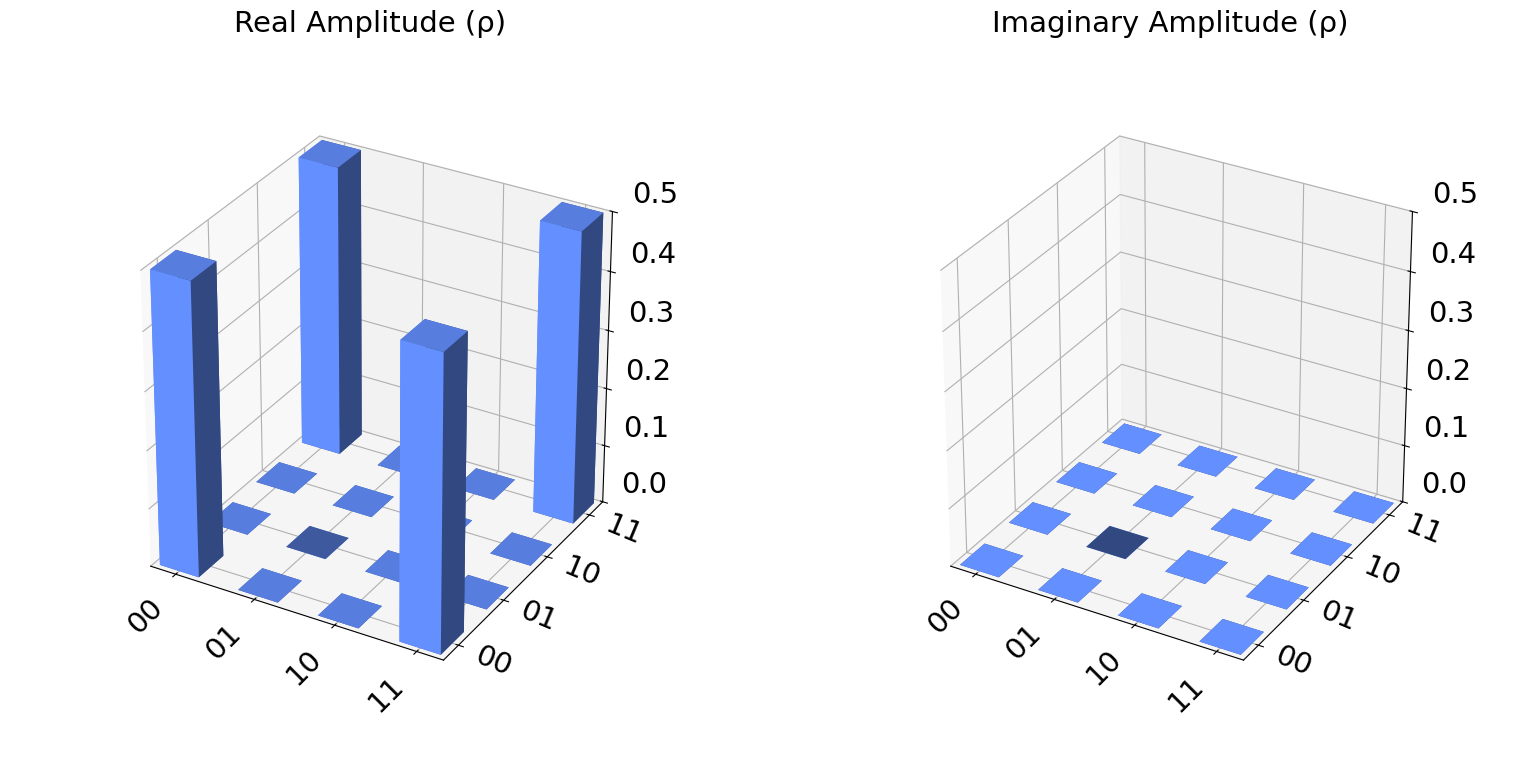

In [ ]:
plot_state_city(answer)

If one wants to prepare the qubits in other initial states, it could be useful to turn out circuit into a function that can be used to easily append the required gates to a given circuit.

In [ ]:
def bell(qc):
    qc.h(0)
    qc.cx(0,1)

In [ ]:
init_circ = QuantumCircuit(2)
init_circ.x(0)
init_circ.barrier()
bell(init_circ)
init_circ.draw()

┌───┐ ░ ┌───┐     
q_0: ┤ X ├─░─┤ H ├──■──
     └───┘ ░ └───┘┌─┴─┐
q_1: ──────░──────┤ X ├
           ░      └───┘

This initializes the qubits in the $|01\rangle$ state (remember that here $q_0$ comes _last_) and runs them through our circuit. You could then recover the output state by the above procedure as we did in class.

Note: you can also easily recover the global unitary matrix corresponding to the quantum circuit by sending it to the `unitary_simulator`.

In [ ]:
unit_simulator = Aer.get_backend('unitary_simulator')

job = unit_simulator.run(circ)

job.result().get_unitary()

Operator([[ 0.70710678+0.00000000e+00j,  0.70710678-8.65956056e-17j,
            0.        +0.00000000e+00j,  0.        +0.00000000e+00j],
          [ 0.        +0.00000000e+00j,  0.        +0.00000000e+00j,
            0.70710678+0.00000000e+00j, -0.70710678+8.65956056e-17j],
          [ 0.        +0.00000000e+00j,  0.        +0.00000000e+00j,
            0.70710678+0.00000000e+00j,  0.70710678-8.65956056e-17j],
          [ 0.70710678+0.00000000e+00j, -0.70710678+8.65956056e-17j,
            0.        +0.00000000e+00j,  0.        +0.00000000e+00j]],
         input_dims=(2, 2), output_dims=(2, 2))


 **To do**: construct the following circuit
 ![image.png](attachment:image.png)

 where $T = P(\frac{\pi}{4}) = \begin{bmatrix} 1 & 0 \\ 0 & e^{i \frac{\pi}{4}} \end{bmatrix}$ (directly available as a `t` gate, whereas its inverse $T^\dagger = P(-\frac{\pi}{4})$ is `tdg`).

 Write down its $8 \times 8$ unitary matrix representation. Do you recognize this $3$-qubit gate? Try to confirm your answer.

In [ ]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from numpy import pi

qreg_q = QuantumRegister(3, 'q')
creg_c = ClassicalRegister(4, 'c')
circuit = QuantumCircuit(qreg_q, creg_c)

circuit.h(qreg_q[2])
circuit.cx(qreg_q[1], qreg_q[2])
circuit.tdg(qreg_q[2])
circuit.cx(qreg_q[0], qreg_q[2])
circuit.t(qreg_q[2])
circuit.cx(qreg_q[1], qreg_q[2])
circuit.tdg(qreg_q[2])
circuit.barrier(qreg_q[1])
circuit.t(qreg_q[1])
circuit.cx(qreg_q[0], qreg_q[2])
circuit.t(qreg_q[2])
circuit.cx(qreg_q[0], qreg_q[1])
circuit.h(qreg_q[2])
circuit.tdg(qreg_q[1])
circuit.t(qreg_q[0])
circuit.cx(qreg_q[0], qreg_q[1])

circuit.draw()

┌───┐      
q_0: ───────────────────■──────────────────────────■────■───┤ T ├───■──
                        │               ░   ┌───┐  │  ┌─┴─┐┌┴───┴┐┌─┴─┐
q_1: ───────■───────────┼─────────■─────░───┤ T ├──┼──┤ X ├┤ Tdg ├┤ X ├
     ┌───┐┌─┴─┐┌─────┐┌─┴─┐┌───┐┌─┴─┐┌─────┐└───┘┌─┴─┐├───┤└┬───┬┘└───┘
q_2: ┤ H ├┤ X ├┤ Tdg ├┤ X ├┤ T ├┤ X ├┤ Tdg ├─────┤ X ├┤ T ├─┤ H ├──────
     └───┘└───┘└─────┘└───┘└───┘└───┘└─────┘     └───┘└───┘ └───┘      
c: 4/══════════════════════════════════════════════════════════════════

In [ ]:
import numpy as np

unit_simulator = Aer.get_backend('unitary_simulator')
job = unit_simulator.run(circuit)
mat = job.result().get_unitary()

# Get 8x8 unitary matrix
print("Circuit unitary:\n", np.asarray(mat))

Circuit unitary:
 [[ 1.00000000e+00-6.12323400e-17j  0.00000000e+00+0.00000000e+00j
   0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j
   2.22044605e-16+3.92523115e-17j  0.00000000e+00+0.00000000e+00j
   0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j]
 [ 0.00000000e+00+0.00000000e+00j  1.00000000e+00+0.00000000e+00j
   0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j
   0.00000000e+00+0.00000000e+00j -5.55111512e-17+1.00484651e-16j
   0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j]
 [ 0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j
   1.00000000e+00-1.11022302e-16j  0.00000000e+00+0.00000000e+00j
   0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j
  -3.92523115e-17+3.92523115e-17j  0.00000000e+00+0.00000000e+00j]
 [ 0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j
   0.00000000e+00+0.00000000e+00j  1.57009246e-16+7.85046229e-17j
   0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.000

## B) Grover with $N = 4$

Let us implement Grover's search algorithm in a space of size $N = 4$ (hence written on $n = 2$ qubits). Suppose to fix ideas we want to find the element $\omega = 10$ in the set $X = \{00, 01, 10, 11\}$.

![image.png](attachment:image.png)

In this situation, we are able to construct directly the phase-flip oracle $U_w$ without the need of an ancillary qubit, so let us just get rid of it. The first thing we need to do is intialize our first 2 qubits to the equal superposition state

$$ |s\rangle = \frac{|00\rangle + |01\rangle + |10\rangle + |11\rangle}{2}. $$

In [ ]:
def full_h(qc):
    for i in range(qc.num_qubits):
        qc.h(i)

In [ ]:
circ = QuantumCircuit(2)
full_h(circ)
circ.draw()

┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     └───┘

For $n = 2$, the equal superposition state $|s\rangle$ makes an initial angle $\frac{\theta}{2} = \arcsin \frac{1}{\sqrt{4}} = \arcsin \frac{1}{2} = \frac{\pi}{6}$ with the horizontal $|s'\rangle$ in the plan spanned by $|s\rangle$ and $|\omega\rangle$. After one rotation of $\theta = \frac{\pi}{3}$, an angle of $\frac{\pi}{2}$ is reached so the state will be exactly $|\omega\rangle$ after a single iteration of the phase amplification stage.

So we only need to apply the $U_\omega$ phase flip oracle, to invert the phase of $|10\rangle$ and leave the 3 other basis vectors untouched. You may check that this can be achieved using a combination of $X$ and controlled-$Z$ gates:

In [ ]:
def oracle(qc):
    qc.x(0)
    qc.cz(0,1)
    qc.x(0)

In [ ]:
circ.barrier()
oracle(circ)
circ.draw()

┌───┐ ░ ┌───┐   ┌───┐
q_0: ┤ H ├─░─┤ X ├─■─┤ X ├
     ├───┤ ░ └───┘ │ └───┘
q_1: ┤ H ├─░───────■──────
     └───┘ ░

We then need to apply the $U_s = H^{\otimes 2} \, U_0 \, H^{\otimes 2}$ reflection operator (the global sign can be safely discarded). Again $U_0$ can be achieved using a combination of $X$ and $CZ$ gates.

In [ ]:
def full_x(qc):
    for i in range(qc.num_qubits):
        qc.x(i)

def g(qc):
    # Hadamard gates
    full_h(qc)
    # U_0
    full_x(qc)
    qc.cz(0,1)
    full_x(qc)
    # Hadamard gates
    full_h(qc)

In [ ]:
circ.barrier()
g(circ)
circ.draw()

┌───┐ ░ ┌───┐   ┌───┐ ░ ┌───┐┌───┐   ┌───┐┌───┐
q_0: ┤ H ├─░─┤ X ├─■─┤ X ├─░─┤ H ├┤ X ├─■─┤ X ├┤ H ├
     ├───┤ ░ └───┘ │ └───┘ ░ ├───┤├───┤ │ ├───┤├───┤
q_1: ┤ H ├─░───────■───────░─┤ H ├┤ X ├─■─┤ X ├┤ H ├
     └───┘ ░               ░ └───┘└───┘   └───┘└───┘

We can confirm that the output state should be $|10\rangle$ with probability 1:

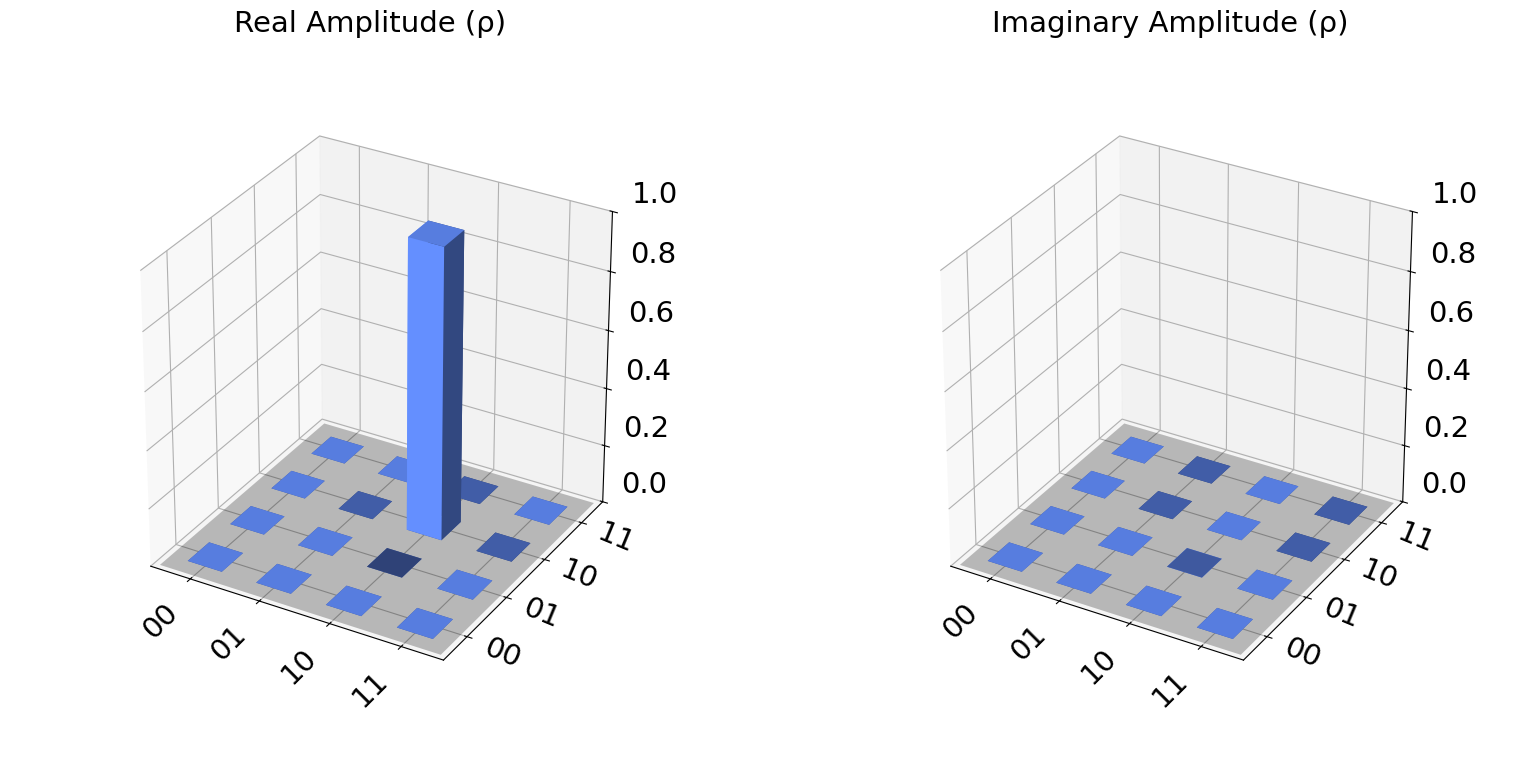

In [ ]:
state_simulator = Aer.get_backend('statevector_simulator')

job = state_simulator.run(circ)
answer = job.result().get_statevector()

plot_state_city(answer)

Let us now add measurements and _simulate_ the execution of the algorithm:

In [ ]:
circ.measure_all()
circ.draw()

┌───┐ ░ ┌───┐   ┌───┐ ░ ┌───┐┌───┐   ┌───┐┌───┐ ░ ┌─┐   
   q_0: ┤ H ├─░─┤ X ├─■─┤ X ├─░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░─┤M├───
        ├───┤ ░ └───┘ │ └───┘ ░ ├───┤├───┤ │ ├───┤├───┤ ░ └╥┘┌─┐
   q_1: ┤ H ├─░───────■───────░─┤ H ├┤ X ├─■─┤ X ├┤ H ├─░──╫─┤M├
        └───┘ ░               ░ └───┘└───┘   └───┘└───┘ ░  ║ └╥┘
meas: 2/═══════════════════════════════════════════════════╩══╩═
                                                           0  1

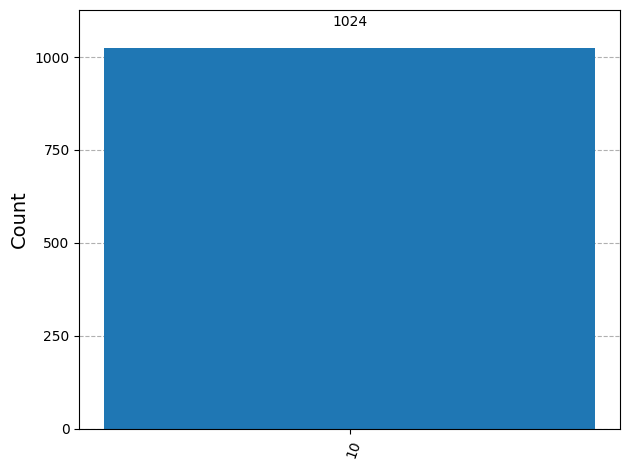

In [ ]:
qasm_simulator = Aer.get_backend('qasm_simulator')

job = qasm_simulator.run(circ, shots=1024)

results = job.result()
answer = results.get_counts()
plot_histogram(answer)

We can also send our circuit to an actual quantum computer, using the API token from your IBM Quantum account (job will be run asynchronously but it may take some time):

In [ ]:
api_key = "fWwuKyj7VbwSfyrC7MsbAJKm-MxcpjIntTsu5rAVZsOf"

In [ ]:
service = QiskitRuntimeService(channel="ibm_quantum_platform", token=api_key)

backend = service.least_busy(operational=True, simulator=False)

print("Jobs will be running on %s" % backend.name)

qiskit_runtime_service._discover_account:WARNING:2026-01-28 15:21:01,434: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-01-28 15:21:03,431: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService().
qiskit_runtime_service.backends:WARNING:2026-01-28 15:21:03,736: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-01-28 15:21:05,196: Using instance: open-instance, plan: open


Jobs will be running on ibm_torino


In [ ]:
# non-blocking, you may continue to evalue other cells

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
new_circuit = pm.run(circ)

sampler = Sampler(mode=backend)

job = sampler.run([new_circuit])

In [ ]:
# check if job is done
print("Job ID: %s" % job.job_id())
print("Status: %s" % job.status())

Job ID: d5t2ipsbmr9c739mis50
Status: DONE


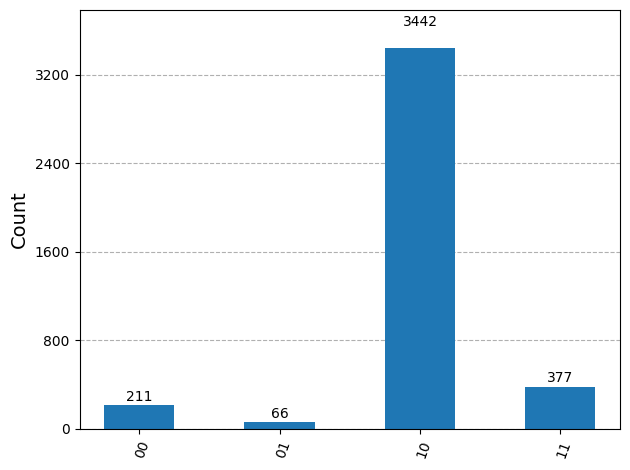

In [ ]:
# waiting for the job to finish, however, *is* blocking, do not run until job is done
results = job.result()[0]
answer = results.data.meas.get_counts()
plot_histogram(answer)

Some (gate + measurement) errors are to be expected!

**To do**: Go through the same process again, this time looking for another element $\omega \in X$ of your choice.

> Ajouter une citation



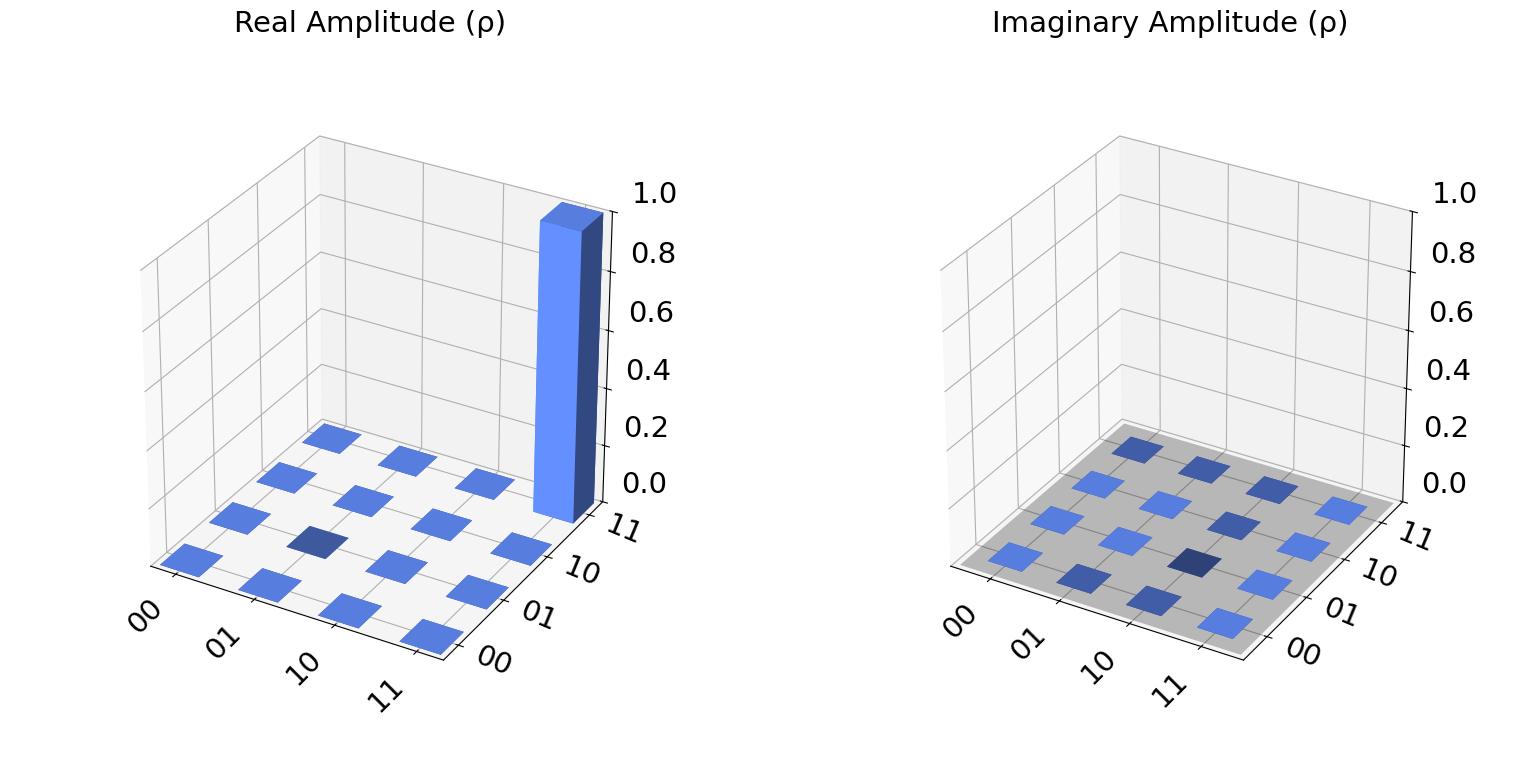

In [ ]:
circ2 = QuantumCircuit(2)
full_h(circ2)
circ2.draw()

def oracle(qc):
    qc.cz(0,1)

circ2.barrier()
oracle(circ2)
circ2.draw()

def full_x(qc):
    for i in range(qc.num_qubits):
        qc.x(i)

def g(qc):
    # Hadamard gates
    full_h(qc)
    # U_0
    full_x(qc)
    qc.cz(0,1)
    full_x(qc)
    # Hadamard gates
    full_h(qc)

circ2.barrier()
g(circ2)
circ2.draw()

state_simulator = Aer.get_backend('statevector_simulator')

job = state_simulator.run(circ2)
answer = job.result().get_statevector()

plot_state_city(answer)

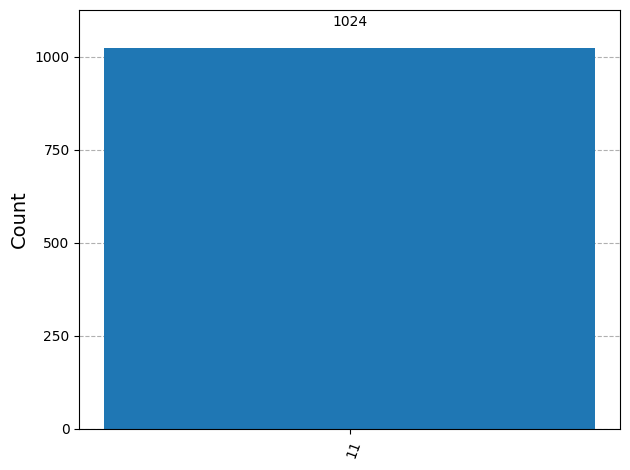

In [ ]:
circ2.measure_all()
circ2.draw()

qasm_simulator = Aer.get_backend('qasm_simulator')

job = qasm_simulator.run(circ2, shots=1024)

results = job.result()
answer = results.get_counts()
plot_histogram(answer)

## C) Grover with $N = 8$

**Todo**: a) Implement a Grover search on $n=3$ qubits for the state $\omega = 111$. Here the phase-flip $U_\omega$ oracle can be implemented as a controlled-controlled-$Z$ gate, constructed from a $CCX$ (Toffoli) gate and the fact that $Z = HXH$:

In [ ]:
n = 3
ccz = QuantumCircuit(n)
ccz.h(n-1)
ccz.mcx(list(range(n-1)), n-1)  # multi-controlled Toffoli
ccz.h(n-1)
ccz.draw()

q_0: ───────■───────
            │       
q_1: ───────■───────
     ┌───┐┌─┴─┐┌───┐
q_2: ┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘

You may experiment with different numbers $k$ of iterations of the amplitude amplification step $(G U_\omega)^k $ and compare with the optimal value predicted by theory.

In [ ]:
def oracle(qc):
  n = qc.num_qubits
  full_x(qc)
  qc.h(n-1)
  qc.mcx(list(range(n-1)), n-1)
  qc.h(n-1)

circ_ccz = QuantumCircuit(3)
oracle(circ_ccz)
circ_ccz.draw()

┌───┐               
q_0: ┤ X ├───────■───────
     ├───┤       │       
q_1: ┤ X ├───────■───────
     ├───┤┌───┐┌─┴─┐┌───┐
q_2: ┤ X ├┤ H ├┤ X ├┤ H ├
     └───┘└───┘└───┘└───┘

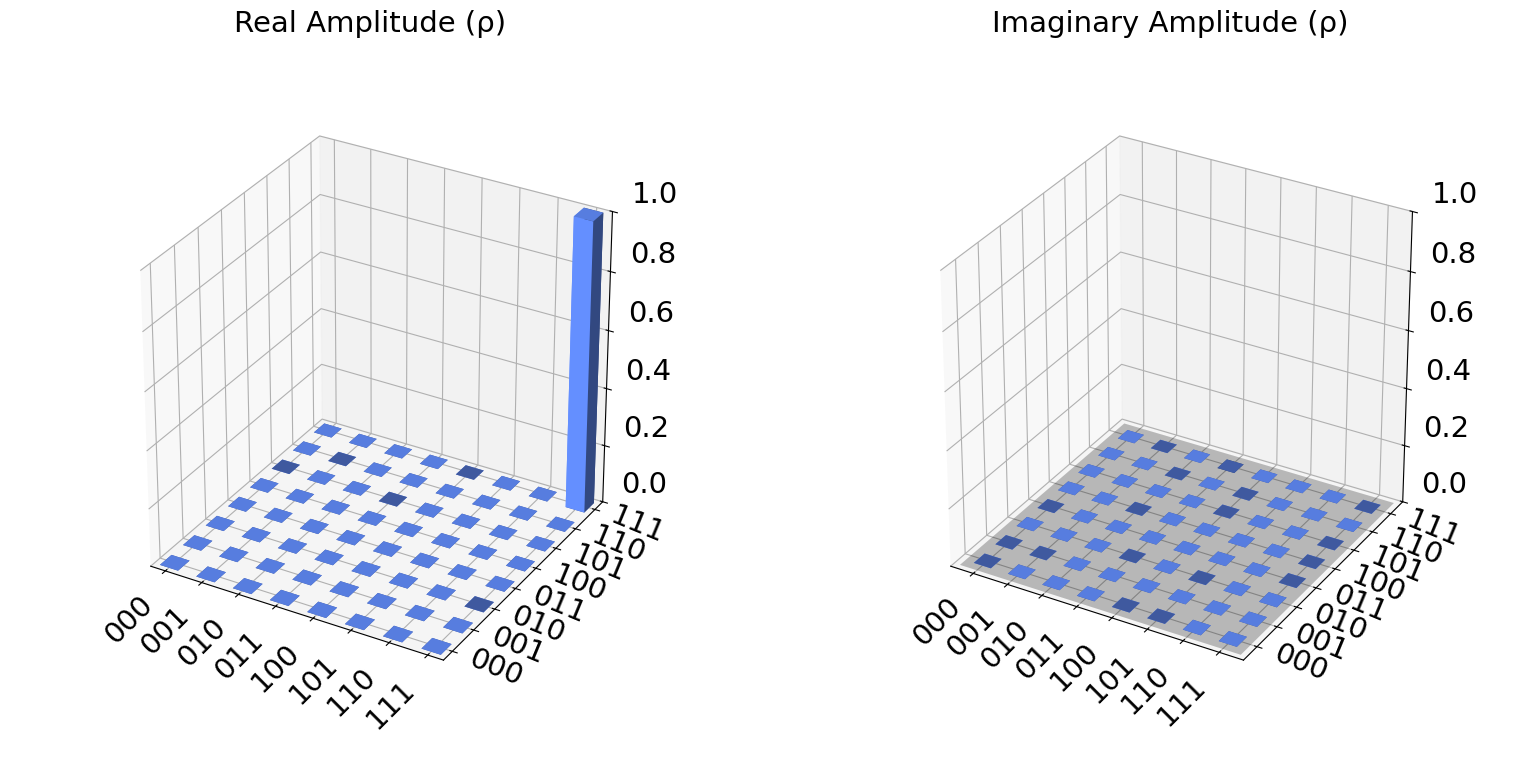

In [ ]:
state_simulator = Aer.get_backend('statevector_simulator')

job = state_simulator.run(circ_ccz)
answer = job.result().get_statevector()

plot_state_city(answer)

b) Same question, but this time using the following phase-flip oracle: ![image.png](attachment:image.png) What is the optimal number of iterations this time? Can you explain what is happening?

In [ ]:
def phase_flip_oracle(qc):
    qc.x(1)
    qc.x(2)
    qc.swap(0, 2)
    qc.swap(1, 2)
    qc.x(1)
    qc.x(2)

circ_flip = QuantumCircuit(3)
phase_flip_oracle(circ_flip)
circ_flip.draw()

q_0: ──────X─────────
     ┌───┐ │    ┌───┐
q_1: ┤ X ├─┼──X─┤ X ├
     ├───┤ │  │ ├───┤
q_2: ┤ X ├─X──X─┤ X ├
     └───┘      └───┘

In [ ]:
n = 3 # 3 bits
N = 2**n

k = ( pi * N**(1/2) ) / 4
print(f"Nombre optimal d'itérations: {k}")

Nombre optimal d'itérations: 2.221441469079183
